## Exercise 1: Mass ratio over time

I plotted the mass ratio $q = M_2/M_1$ to see when Star 2 became more massive than Star 1. The ratio starts at $31/35 \approx 0.89$, and the horizontal line at $q = 1$ marks where the two stars have equal masses.

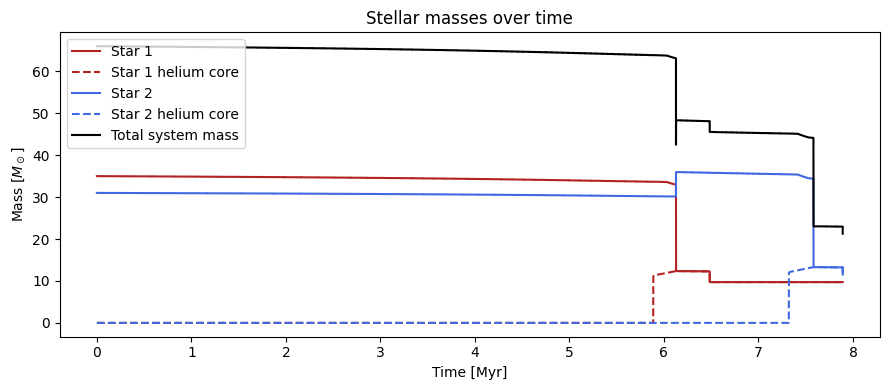

In [17]:
STAR_COLORS = {1: "firebrick", 2: "royalblue"}
time = df["Time"]

def plot_masses(ax):
    for star, color in STAR_COLORS.items():
        ax.plot(time, df[f"Mass({star})"], color=color, label=f"Star {star}")
        ax.plot(
            time, df[f"Mass_He_Core({star})"],
            color=color, linestyle="--", label=f"Star {star} helium core",
        )
    ax.set_ylabel(r"Mass [$M_\odot$]")

fig, ax = plt.subplots(figsize=(9, 4))
plot_masses(ax)
ax.plot(time, df["Mass(1)"] + df["Mass(2)"], color="black", label="Total system mass")
ax.set_xlabel("Time [Myr]")
ax.set_title("Stellar masses over time")
ax.legend()
fig.tight_layout()
plt.show()

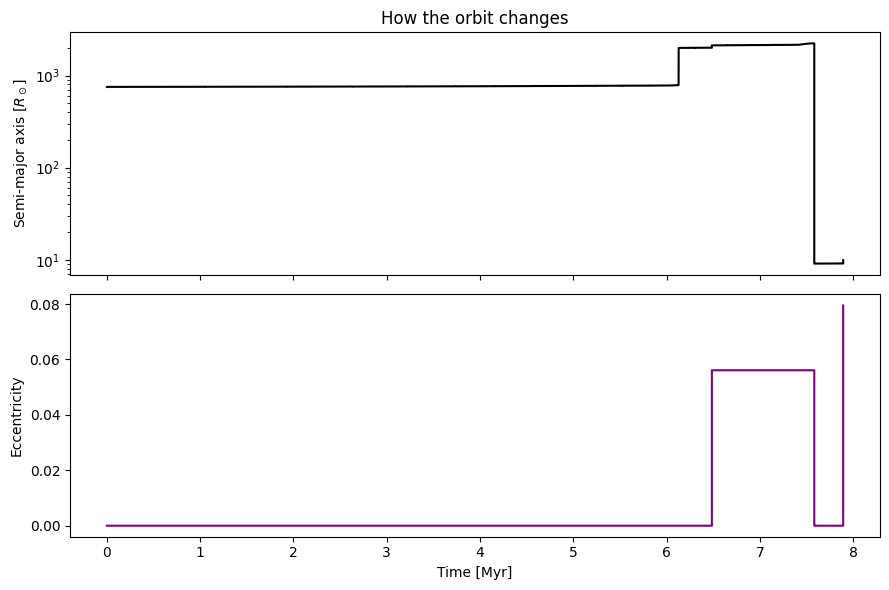

Just before the common envelope: 2109.80 solar radii
At the first common-envelope record: 9.09 solar radii
Orbital shrinkage factor: 232.1


In [11]:
def plot_separation(ax):
    ax.plot(time, df["SemiMajorAxis"], color="black")
    ax.set_yscale("log")
    ax.set_ylabel(r"Semi-major axis [$R_\odot$]")

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 6))

plot_separation(axes[0])
axes[0].set_title("How the orbit changes")

axes[1].plot(time, df["Eccentricity"], color="purple")
axes[1].set_ylabel("Eccentricity")
axes[1].set_xlabel("Time [Myr]")

fig.tight_layout()
plt.show()

in_ce = df["MT_History"].isin([3, 4, 5])
ce_starts = df.index[in_ce & ~in_ce.shift(fill_value=False)]

if len(ce_starts) > 0 and ce_starts[0] > 0:
    i = ce_starts[0]
    before = df["SemiMajorAxis"].iloc[i - 1]
    during = df["SemiMajorAxis"].iloc[i]

    print(f"Just before the common envelope: {before:.2f} solar radii")
    print(f"At the first common-envelope record: {during:.2f} solar radii")
    print(f"Orbital shrinkage factor: {before / during:.1f}")
else:
    print("No common-envelope transition with a preceding row was found.")

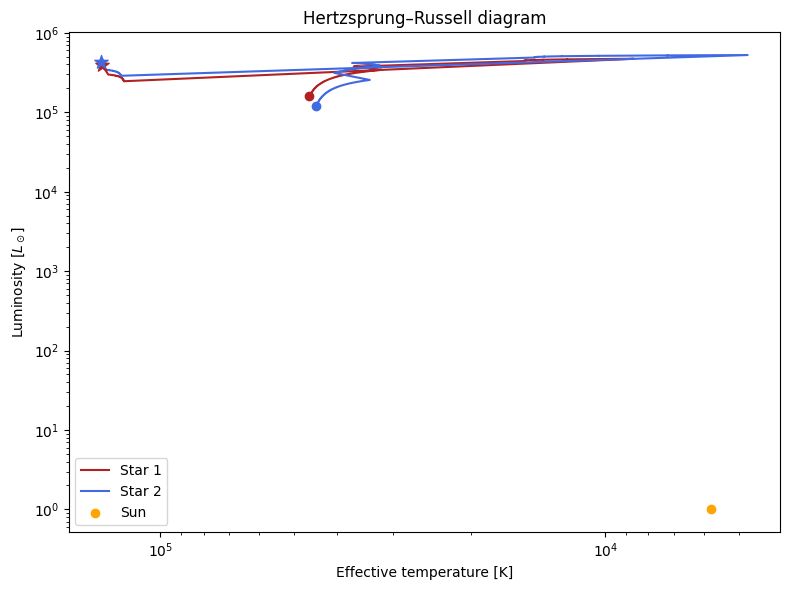

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))

for star, color in STAR_COLORS.items():
    temperature = df[f"Teff({star})"]
    luminosity = df[f"Luminosity({star})"]
    stellar_type = df[f"Stellar_Type({star})"]

    has_stellar_surface = stellar_type.isin(list(range(10)) + [16])
    valid = has_stellar_surface & temperature.gt(0) & luminosity.gt(0)
    track = df.loc[valid]

    if not track.empty:
        x = track[f"Teff({star})"]
        y = track[f"Luminosity({star})"]

        ax.plot(x, y, color=color, label=f"Star {star}")
        ax.scatter(x.iloc[0], y.iloc[0], color=color, marker="o", zorder=3)
        ax.scatter(x.iloc[-1], y.iloc[-1], color=color, marker="*", s=100, zorder=3)

ax.scatter(5772, 1, color="orange", label="Sun", zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
ax.invert_xaxis()
ax.set_xlabel("Effective temperature [K]")
ax.set_ylabel(r"Luminosity [$L_\odot$]")
ax.set_title("Hertzsprung–Russell diagram")
ax.legend()
fig.tight_layout()
plt.show()

In [14]:
def plot_radii(ax):
    for star, color in STAR_COLORS.items():
        ax.plot(
            time, df[f"Radius({star})"],
            color=color, label=f"Star {star} radius",
        )
        ax.plot(
            time, df[f"RocheLobe({star})"],
            color=color, linestyle="--", label=f"Star {star} Roche lobe",
        )

    ax.set_yscale("log")
    ax.set_ylabel(r"Radius [$R_\odot$]")


def plot_separation(ax):
    ax.plot(time, df["SemiMajorAxis"], color="black")
    ax.set_yscale("log")
    ax.set_ylabel(r"Semi-major axis [$R_\odot$]")

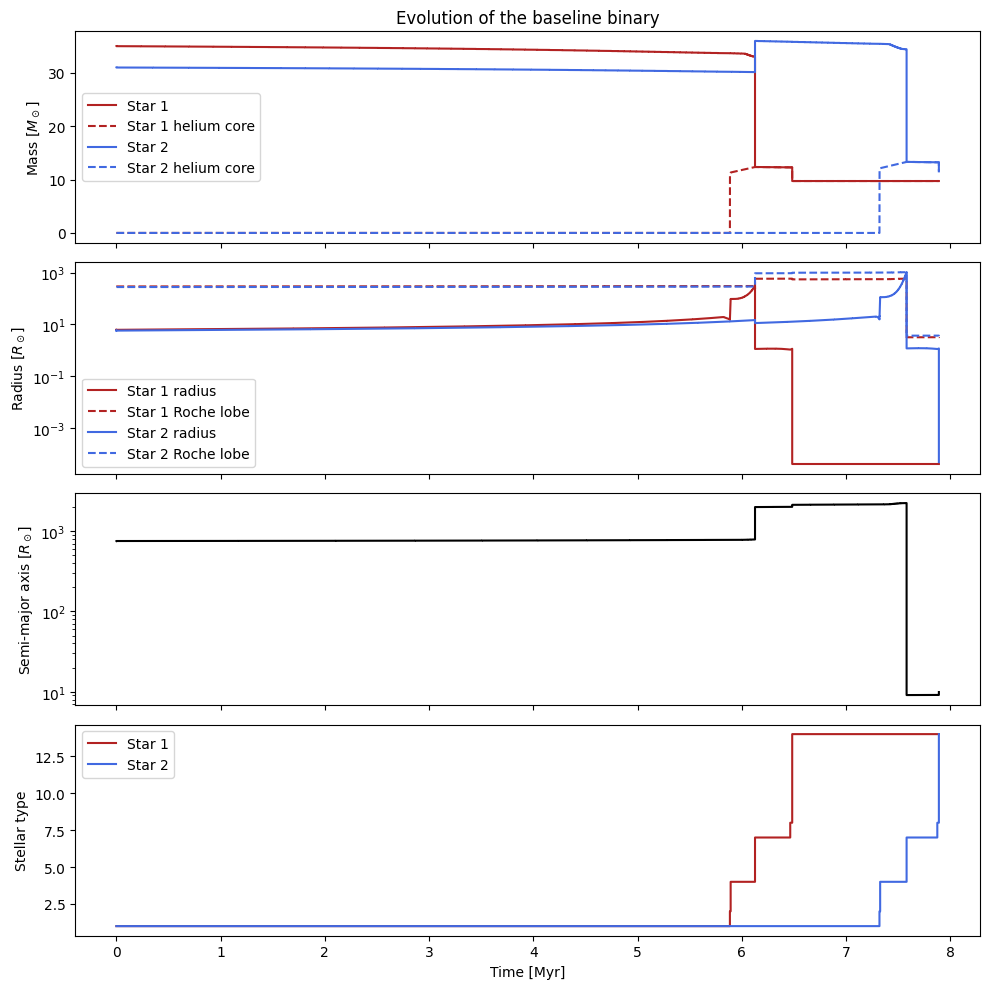

In [15]:
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(10, 10))

plot_masses(axes[0])
plot_radii(axes[1])
plot_separation(axes[2])

for star, color in STAR_COLORS.items():
    axes[3].step(
        time, df[f"Stellar_Type({star})"],
        where="post", color=color, label=f"Star {star}",
    )

axes[0].set_title("Evolution of the baseline binary")
axes[3].set_ylabel("Stellar type")
axes[3].set_xlabel("Time [Myr]")

for ax in (axes[0], axes[1], axes[3]):
    ax.legend()

fig.tight_layout()
plt.show()

First sample with q > 1: 6.13 Myr


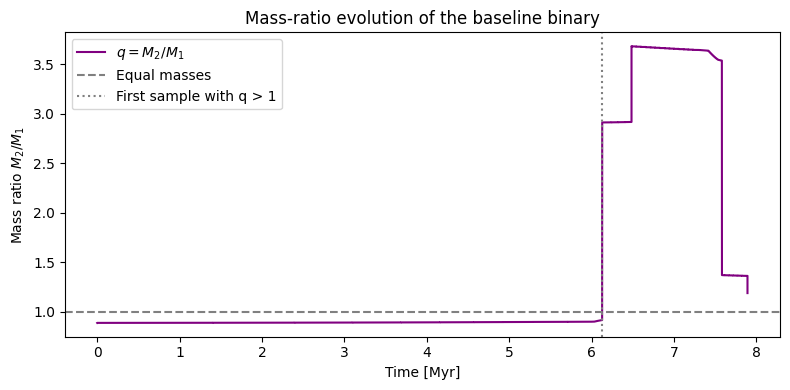

In [16]:
q = df["Mass(2)"] / df["Mass(1)"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df["Time"], q, color="purple", label=r"$q = M_2/M_1$")
ax.axhline(1, color="gray", linestyle="--", label="Equal masses")

above_one = df.loc[q > 1, "Time"]
if not above_one.empty:
    first_time = above_one.iloc[0]
    ax.axvline(first_time, color="gray", linestyle=":", label="First sample with q > 1")
    print(f"First sample with q > 1: {first_time:.2f} Myr")

ax.set_xlabel("Time [Myr]")
ax.set_ylabel(r"Mass ratio $M_2/M_1$")
ax.set_title("Mass-ratio evolution of the baseline binary")
ax.legend()
fig.tight_layout()
plt.show()

## Exercise 2 

I will compare three simulations with my baseline binary, which starts with
masses of $35\,M_\odot$ and $31\,M_\odot$, metallicity $Z = 0.001$,
a separation of $3.5$ AU, and a circular orbit. For each run, I will
change only the settings listed below.

### My predictions

1. **Higher metallicity ($Z = 0.02$).** I expect stronger stellar winds
   to remove more mass. If both stars still form black holes, I predict
   that the black holes will be lighter than in the baseline run.

2. **Wider orbit ($35$ AU).** I expect the stars to be less likely to
   fill their Roche lobes and enter a common envelope. If they form two
   black holes that stay bound in a wide orbit, I expect them to take
   longer than the age of the universe to merge.

3. **Equal masses ($33\,M_\odot$ each).** I expect both stars to evolve
   on similar timescales. I'm unsure which star, if either, will be
   stripped first, so I'll check the order of events in the simulation.

## Exercise 3: 

I will use the final black hole masses and orbital separation from the
baseline simulation to estimate the merger time. I will then repeat the
calculation using the separation before the common envelope, keeping
the black hole masses fixed so I can see the effect of separation alone.

In [18]:
G = 6.67430e-11
c = 2.99792458e8
M_SUN = 1.98892e30
R_SUN = 6.957e8
SECONDS_PER_GYR = 3.15576e16

def merger_time_gyr(mass1_solar, mass2_solar, separation_solar):
    # Convert solar masses and solar radii to SI units.
    m1 = mass1_solar * M_SUN
    m2 = mass2_solar * M_SUN
    a = separation_solar * R_SUN

    # Merger time for a circular orbit.
    time_seconds = (5 * c**5 * a**4) / (256 * G**3 * m1 * m2 * (m1 + m2))
    return time_seconds / SECONDS_PER_GYR

final = df.iloc[-1]
m1 = final["Mass(1)"]
m2 = final["Mass(2)"]
a_final = final["SemiMajorAxis"]

t_final = merger_time_gyr(m1, m2, a_final)
t_wide = merger_time_gyr(m1, m2, 2110)

print(f"Final black hole masses: {m1:.2f} and {m2:.2f} solar masses")
print(f"Final separation: {a_final:.2f} solar radii")
print(f"Merger time at the final separation: {t_final:.3f} Gyr")
print(f"Merger time at 2,110 solar radii: {t_wide:.2e} Gyr")

Final black hole masses: 9.73 and 11.54 solar masses
Final separation: 9.91 solar radii
Merger time at the final separation: 0.606 Gyr
Merger time at 2,110 solar radii: 1.25e+09 Gyr


### Results

The baseline simulation ended with two black holes of $9.73$ and
$11.54\,M_\odot$, with a semi-major axis of $9.91\,R_\odot$.
Using the circular-orbit approximation, I estimated a merger time
of 0.606 Gyr (606 million years), which is shorter than the age
of the universe, about 13.8 Gyr.

When I kept the final black hole masses fixed and used the
pre-common-envelope separation of $2{,}110\,R_\odot$, the estimated
merger time increased to **$1.25 \times 10^9$ Gyr. At fixed masses,
the merger time scales as $a^4$, so the orbital shrinkage during the
common envelope made it possible for the black holes to merge within
the age of the universe in this simulation.